In [1]:
from pyrocko import util, model, io, trace, moment_tensor, gmtpy,orthodrome
import pyrocko.moment_tensor as pmt
from pyrocko import orthodrome as od
from pyrocko.guts import load

# from seiscloud import plot as scp
# from seiscloud import cluster as scc
import numpy as np
import os
# import shutil
import matplotlib.pyplot as plt

import re
from pathlib import Path
from datetime import datetime

import yaml

# CLASS TO LOAD .YAML FILES AND READ PARAMENTER RESULTS
class IgnoreTagsLoader(yaml.SafeLoader):
    pass

def ignore_unknown(loader, tag_suffix, node):
    if isinstance(node, yaml.MappingNode):
        return loader.construct_mapping(node)
    elif isinstance(node, yaml.SequenceNode):
        return loader.construct_sequence(node)
    else:
        return loader.construct_scalar(node)

IgnoreTagsLoader.add_multi_constructor('!', ignore_unknown)

In [2]:
workdir='../' 
reportdir=os.path.join(workdir,'report')                                

catdir=os.path.join(workdir,'CAT')
catname=os.path.join(catdir,'catalogue_flegrei_VLP.pf')                 # CHANGE
refevents=model.load_events(catname)
mttargets = [ev for ev in refevents]

badmtsols = ['']    # exclude some events
print(f'Catalogue: {catname}')
print('All events in catalogue:', len(mttargets))
goodmttargets = [ev for ev in mttargets if ev.name not in badmtsols]
print('Good events in catalogue:', len(goodmttargets))

# Insert inversions names
inversions= ['cmt_composite_LF_std_']                                    # CHANGE

# Insert source prefixes 
par_names = ['time',]
# add:
#   'north_shift','east_shift', 
#   'depth','magnitude',
#   'rmnn','rmee','rmdd','rmne','rmnd','rmed',
#   'duration','frequency',
#   'strike1','dip1','rake1'

print(f'\nInversions selected: {inversions}')

#reportdir=os.path.join(workdir,'report') # pre-defined
#reportdir = '/Users/giaco/UNI/PhD_CODE/GIT/CAMPI_FLEGREI_moment_tensor/report'
reportdir = '/Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report'

Catalogue: ../CAT/catalogue_flegrei_VLP.pf
All events in catalogue: 19
Good events in catalogue: 19

Inversions selected: ['cmt_composite_LF_std_']


In [3]:
# VT results
source_prefixes = ['vt']                                           
print(f'Sources extracted: {source_prefixes}')

vt_stats={}

counter_total_reports = 0
for ev in goodmttargets:
    counter = 0
    for vrs in inversions: # main report
        targetdir = os.path.join(reportdir, ev.name, vrs + ev.name)
        #if not os.path.isdir(targetdir):
            #print(ev.name, 'missing report dir', targetdir)
        if os.path.isdir(targetdir):
            counter += 1
            fname = os.path.join(targetdir, 'stats.yaml')     # results
            if os.path.isfile(fname):
                # Read file
                with open(fname, 'r') as f:
                    data = yaml.load(f, Loader=IgnoreTagsLoader)    # unsing loader class
                
                # acces 'paramenter_stats_list'
                parameter_stats = data['parameter_stats_list']
                #print(parameter_stats)
                for pref in source_prefixes:
                    vt_stats[ev.name]={pref +'.'+ par :0 for par in par_names}
                for p in parameter_stats:
                    if p['name'] in list(vt_stats[ev.name].keys()):
                        #CHANGE: choose values to extract
                        vt_stats[ev.name][p['name']]= {'best' : float( f"{p['best']:.8g}" ),   
                                                        'percentile16' : float( f"{p['percentile16']:.8g}" ),
                                                        'percentile84' : float( f"{p['percentile84']:.8g}" ),
                                                        'mean' : float( f"{p['mean']:.8g}" ),
                                                        'std' : float( f"{p['std']:.8g}" )
                                                        }
                        # print values
                        #print(p['name'], p['best'], p['percentile16'], p['percentile84'])

    if counter == 0:
        print(f'WARNING: {ev.name} does not have any report directories!')
    elif counter > 1:
        print(f'WARNING: {ev.name} has MULTIPLE report directories!')
    else:
        print(f'NICE! {ev.name} has report directory: {targetdir}')
        counter_total_reports += 1

print(f'\nTotal events with report directories: {counter_total_reports} out of {len(goodmttargets)}')

Sources extracted: ['vt']
NICE! flegrei_2018_09_18_21_36_41 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2018_09_18_21_36_41/cmt_composite_LF_std_flegrei_2018_09_18_21_36_41
NICE! flegrei_2023_06_11_06_44_25 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_06_11_06_44_25/cmt_composite_LF_std_flegrei_2023_06_11_06_44_25
NICE! flegrei_2023_09_26_07_10_29 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_09_26_07_10_29/cmt_composite_LF_std_flegrei_2023_09_26_07_10_29
NICE! flegrei_2023_10_02_20_08_26 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_10_02_20_08_26/cmt_composite_LF_std_flegrei_2023_10_02_20_08_26
NICE! flegrei_2024_04_27_03_44_56 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2024_04_27_03_44_56/cmt_composite_LF_std_flegrei

In [4]:
# VLP results
source_prefixes = ['vlp']                                         
print(f'Sources extracted: {source_prefixes}')

vlp_stats={}

counter_total_reports = 0
for ev in goodmttargets:
    counter = 0
    for vrs in inversions: # main report
        targetdir = os.path.join(reportdir, ev.name, vrs + ev.name)
        #if not os.path.isdir(targetdir):
            #print(ev.name, 'missing report dir', targetdir)
        if os.path.isdir(targetdir):
            counter += 1
            fname = os.path.join(targetdir, 'stats.yaml')     # results
            if os.path.isfile(fname):
                # Read file
                with open(fname, 'r') as f:
                    data = yaml.load(f, Loader=IgnoreTagsLoader)    # unsing loader class
                
                # acces 'paramenter_stats_list'
                parameter_stats = data['parameter_stats_list']
                #print(parameter_stats)
                for pref in source_prefixes:
                    vlp_stats[ev.name]={pref +'.'+ par :0 for par in par_names}
                for p in parameter_stats:
                    if p['name'] in list(vlp_stats[ev.name].keys()):
                        #CHANGE: choose values to extract
                        vlp_stats[ev.name][p['name']]= {'best' : float( f"{p['best']:.8g}" ),   
                                                        'percentile16' : float( f"{p['percentile16']:.8g}" ),
                                                        'percentile84' : float( f"{p['percentile84']:.8g}" ),
                                                        'mean' : float( f"{p['mean']:.8g}" ),
                                                        'std' : float( f"{p['std']:.8g}" )
                                                        }
                        # print values
                        #print(p['name'], p['best'], p['percentile16'], p['percentile84'])

    if counter == 0:
        print(f'WARNING: {ev.name} does not have any report directories!')
    elif counter > 1:
        print(f'WARNING: {ev.name} has MULTIPLE report directories!')
    else:
        print(f'NICE! {ev.name} has report directory: {targetdir}')
        counter_total_reports += 1

print(f'\nTotal events with report directories: {counter_total_reports} out of {len(goodmttargets)}')

Sources extracted: ['vlp']
NICE! flegrei_2018_09_18_21_36_41 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2018_09_18_21_36_41/cmt_composite_LF_std_flegrei_2018_09_18_21_36_41
NICE! flegrei_2023_06_11_06_44_25 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_06_11_06_44_25/cmt_composite_LF_std_flegrei_2023_06_11_06_44_25
NICE! flegrei_2023_09_26_07_10_29 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_09_26_07_10_29/cmt_composite_LF_std_flegrei_2023_09_26_07_10_29
NICE! flegrei_2023_10_02_20_08_26 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2023_10_02_20_08_26/cmt_composite_LF_std_flegrei_2023_10_02_20_08_26
NICE! flegrei_2024_04_27_03_44_56 has report directory: /Users/giaco/UNI/PhD_CODE/GIT/Grond_composite_test_results/report/flegrei_2024_04_27_03_44_56/cmt_composite_LF_std_flegre

In [5]:
vt_best = []
vt_mean = []
vt_error_best = []

vlp_best = []
vlp_mean = []
vlp_error_best = []

for ev_name in vt_stats:
    best = vt_stats[ev_name]['vt.time']['best']
    vt_best.append(best)
    mean = vt_stats[ev_name]['vt.time']['mean']
    vt_mean.append(mean)
    vt_16 = vt_stats[ev_name]['vt.time']['percentile16']
    vt_84 = vt_stats[ev_name]['vt.time']['percentile84']
    vt_error_best.append( ( np.abs(best-vt_16), np.abs(best-vt_84) ) )

    best = vlp_stats[ev_name]['vlp.time']['best']
    vlp_best.append(best)
    mean = vlp_stats[ev_name]['vlp.time']['mean']
    vlp_mean.append(mean)
    vlp_16 = vlp_stats[ev_name]['vlp.time']['percentile16']
    vlp_84 = vlp_stats[ev_name]['vlp.time']['percentile84']
    vlp_error_best.append( ( np.abs(best-vlp_16), np.abs(best-vlp_84) ) )

vt_best  =np.array(vt_best)
vt_mean  =np.array(vt_mean)
vlp_best =np.array(vlp_best)
vlp_mean =np.array(vlp_mean)

vt_error_best =np.array(vt_error_best)
vt_error_best =vt_error_best.T
vlp_error_best=np.array(vlp_error_best)
vlp_error_best=vlp_error_best.T

index=np.arange(len(vt_best))

(-0.09167119000000001, 1.69134719, -0.8504774105, 1.3170550005)

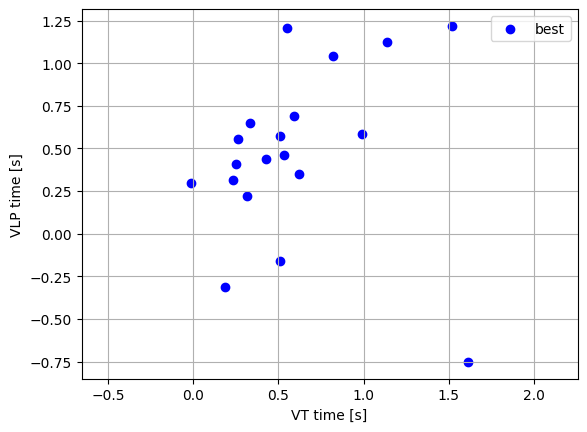

In [28]:
plt.scatter(vt_best, vlp_best, color='blue', label='best')
#plt.scatter(vt_mean, vlp_mean, color='red', label='mean')
plt.xlabel('VT time [s]')
plt.ylabel('VLP time [s]')
plt.legend()
plt.grid()
plt.xlim(-1.0, 2.0)
plt.ylim(-1.0, 2.0)
plt.axis('equal')

VT-VLP best time difference: -0.1309 +- 0.6115 s
VT-VLP mean time difference: -0.0685 +- 0.5083 s


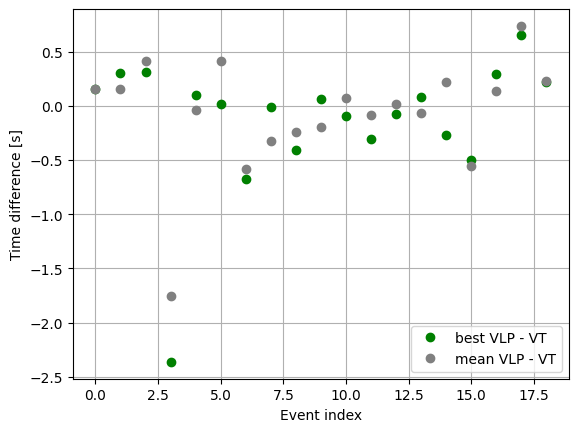

In [18]:
best_diff = vlp_best - vt_best
mean_diff = vlp_mean - vt_mean
plt.plot(best_diff,'o', color='green', label='best VLP - VT')
plt.plot(mean_diff,'o', color='grey', label='mean VLP - VT')
plt.xlabel('Event index')
plt.ylabel('Time difference [s]')
plt.legend()
plt.grid()

print(f'VT-VLP best time difference: {np.mean(best_diff):.4f} +- {np.std(best_diff):.4f} s')
print(f'VT-VLP mean time difference: {np.mean(mean_diff):.4f} +- {np.std(mean_diff):.4f} s')

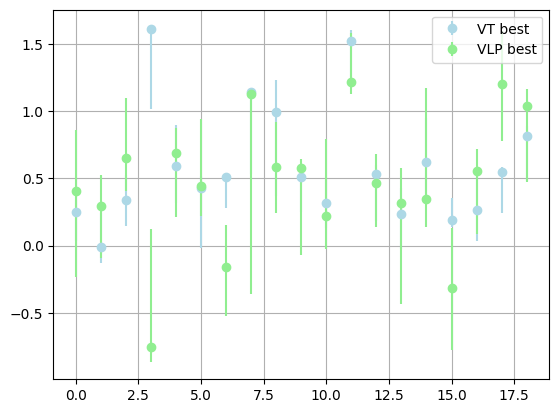

In [17]:
plt.errorbar(index,vt_best, yerr=vt_error_best, fmt='o', color='lightblue', label='VT best')
#plt.plot(index,vt_mean, 'o', color='blue', label='VT mean')

plt.errorbar(index,vlp_best, yerr=vlp_error_best, fmt='o' , color='lightgreen', label='VLP best')
#plt.plot(index,vlp_mean, 'o', color='green', label='VLP mean')

plt.grid()
plt.legend()